# Assignment 9: Explainable AI Using SHAP and LIME

## Aim
To apply Explainable Artificial Intelligence (XAI) techniques—SHAP (SHapley Additive exPlanations) and LIME (Local Interpretable Model-agnostic Explanations)—to interpret predictions made by a machine learning model.

## Objectives
- Train a Random Forest classifier on the Breast Cancer Wisconsin Diagnostic dataset.
- Evaluate the classifier using standard classification metrics.
- Use SHAP to study global feature importance and explain an individual prediction.
- Use LIME to explain the same individual prediction.
- Compare the insights provided by SHAP and LIME.

## Dataset
The Breast Cancer Wisconsin Diagnostic dataset is available through `scikit-learn`. It contains 569 samples and 30 numerical features computed from digitized images of breast mass samples.

The target classes are **malignant** and **benign**. This notebook is for educational purposes only; its model and explanations are not suitable for clinical diagnosis.

## Methods
- Random Forest Classifier
- SHAP `TreeExplainer`
- LIME `LimeTabularExplainer`


## 1. Import Libraries and Set Reproducibility

The required Python libraries are imported for data analysis, model training, visualization, and explainability. NumPy and Pandas are used for numerical operations and data handling, while Matplotlib is used to generate plots. Scikit-learn provides the dataset, Random Forest classifier, and evaluation metrics. SHAP and LIME are used to interpret the model's predictions.

A fixed random state (`RANDOM_STATE = 42`) is used to make dataset splitting and model training reproducible. This helps produce consistent results when the notebook is executed again under the same conditions.


In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import shap
import lime

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print(f"SHAP: {shap.__version__}")
print(f"LIME: {getattr(lime, '__version__', 'version not exposed')}")

d:\College\3rd_Year\MLOPS\Assignments\.mlops\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully.
NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1
SHAP: 0.54.1
LIME: version not exposed


## 2. Load and Explore the Dataset

The Breast Cancer Wisconsin dataset is loaded using scikit-learn. It contains numerical features describing cell nuclei, which are used to classify tumors as malignant or benign. We examine the dataset's dimensions, feature names, and target distribution to understand the data before training the model.

The original target encoding is retained throughout the notebook: `0 = malignant` and `1 = benign`. Keeping this mapping consistent ensures that model predictions, SHAP explanations, LIME explanations, and evaluation labels are interpreted correctly.

In [2]:
dataset = load_breast_cancer()

X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="diagnosis").astype(int)

class_names = ["malignant", "benign"]

print(f"Number of samples: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print("\nClass distribution:")
display(y.map({0: "malignant", 1: "benign"}).value_counts().rename_axis("diagnosis").to_frame("count"))

print("\nFirst five rows:")
display(X.head())

print("\nSummary statistics for the first ten features:")
display(X.describe().T.head(10))

Number of samples: 569
Number of features: 30

Class distribution:


,count
diagnosis,
benign,357
malignant,212



First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Summary statistics for the first ten features:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


## 3. Split the Dataset

The dataset is divided into training and testing sets using an 80:20 ratio. The training set is used to train the Random Forest model, while the testing set evaluates its performance on unseen data.

Stratified splitting is applied to maintain approximately the same proportion of malignant and benign samples in both sets. This helps ensure a representative evaluation of the model.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Number of features: {X_train.shape[1]}")

print("\nTraining class distribution:")
print(y_train.map({0: "malignant", 1: "benign"}).value_counts())

print("\nTesting class distribution:")
print(y_test.map({0: "malignant", 1: "benign"}).value_counts())

Training samples: 455
Testing samples: 114
Number of features: 30

Training class distribution:
diagnosis
benign       285
malignant    170
Name: count, dtype: int64

Testing class distribution:
diagnosis
benign       72
malignant    42
Name: count, dtype: int64


## 4. Train the Random Forest Classifier

A Random Forest classifier is trained using the training dataset. It combines predictions from multiple decision trees to make the final classification, helping improve prediction reliability and reduce overfitting.

The trained model is used to evaluate classification performance on the test set and generate explanations using SHAP and LIME. Keeping the same model throughout ensures that both explainability techniques interpret the predictions of the same classifier.

In [4]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1,
)
model.fit(X_train, y_train)

print("Random Forest model trained successfully.")
print(f"Number of trees: {model.n_estimators}")
print(f"Model classes: {model.classes_}")
print("Class mapping: 0 = malignant, 1 = benign")

Random Forest model trained successfully.
Number of trees: 200
Model classes: [0 1]
Class mapping: 0 = malignant, 1 = benign


## 5. Evaluate the Model

The trained Random Forest model is evaluated on the test dataset using accuracy, macro-averaged precision, recall, and F1-score. These metrics provide an overview of the model's classification performance across both malignant and benign classes.

A confusion matrix is also generated to examine correct and incorrect predictions. It helps identify false negatives, where malignant tumors are predicted as benign, and false positives, where benign tumors are predicted as malignant.

,Metric,Score
0,Accuracy,0.9474
1,Precision (Macro),0.9403
2,Recall (Macro),0.9484
3,F1-score (Macro),0.9440



Classification report:
              precision    recall  f1-score   support

   malignant       0.91      0.95      0.93        42
      benign       0.97      0.94      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114



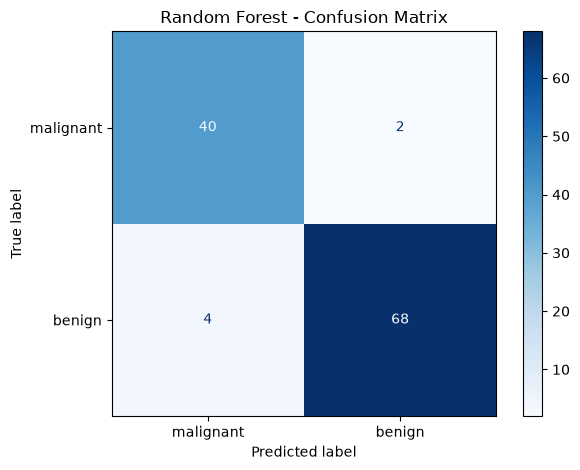

In [5]:
y_pred = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-score (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
}

metrics_df = pd.DataFrame({"Metric": list(metrics.keys()), "Score": list(metrics.values())})
display(metrics_df.style.format({"Score": "{:.4f}"}))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=class_names,
        zero_division=0,
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=class_names,
    cmap="Blues",
)
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

## 6. SHAP Explainability

SHAP (SHapley Additive exPlanations) explains model predictions by showing how individual features contribute to the output. This section uses SHAP to identify important features globally and understand their influence on an individual prediction.

The explanations focus on the **malignant class (class 0)**. Positive SHAP values increase the explained malignant-class output, while negative values decrease it. Since SHAP output formats can vary across library versions, the code handles both three-dimensional and two-dimensional classification outputs.

In [6]:
shap_explainer = shap.TreeExplainer(model)
shap_raw = shap_explainer(X_test)

shap_values_all = np.asarray(shap_raw.values)
base_values_all = np.asarray(shap_raw.base_values)

print("SHAP output shape:", shap_values_all.shape)
print("Base values shape:", base_values_all.shape)

SHAP output shape: (114, 30, 2)
Base values shape: (114, 2)


### 6.1 Select SHAP Values for the Malignant Class

SHAP generates feature contribution values for each sample and class. Since this notebook focuses on predicting malignant tumors, we select the SHAP values corresponding to **class 0 (malignant)** for further analysis.

The selected values are used to visualize global feature importance, examine how features influence predictions across the test set, and explain an individual prediction. This keeps the SHAP analysis consistent with the notebook's target class mapping.

In [7]:
if shap_values_all.ndim == 3:
    # Typical classification shape: samples x features x classes
    malignant_values = shap_values_all[:, :, 0]

    if base_values_all.ndim == 2:
        malignant_base_values = base_values_all[:, 0]
    elif base_values_all.ndim == 1:
        malignant_base_values = base_values_all
    else:
        raise ValueError(f"Unexpected SHAP base-value shape: {base_values_all.shape}")

elif shap_values_all.ndim == 2:
    # Some explainer/model combinations return samples x features
    malignant_values = shap_values_all
    malignant_base_values = base_values_all

else:
    raise ValueError(f"Unexpected SHAP value shape: {shap_values_all.shape}")

shap_malignant = shap.Explanation(
    values=malignant_values,
    base_values=malignant_base_values,
    data=X_test.to_numpy(),
    feature_names=X_test.columns.tolist(),
)

print("Malignant-class SHAP values prepared.")
print("Explanation shape:", shap_malignant.values.shape)

Malignant-class SHAP values prepared.
Explanation shape: (114, 30)


### 6.2 Global Feature Importance

The SHAP bar plot ranks features according to their mean absolute SHAP values across the test set. Features with larger values have a greater average influence on the model's output for the malignant class.

Since absolute values are used, the plot shows the magnitude of each feature's contribution without indicating whether it increases or decreases the model output. This helps identify the most influential features overall.

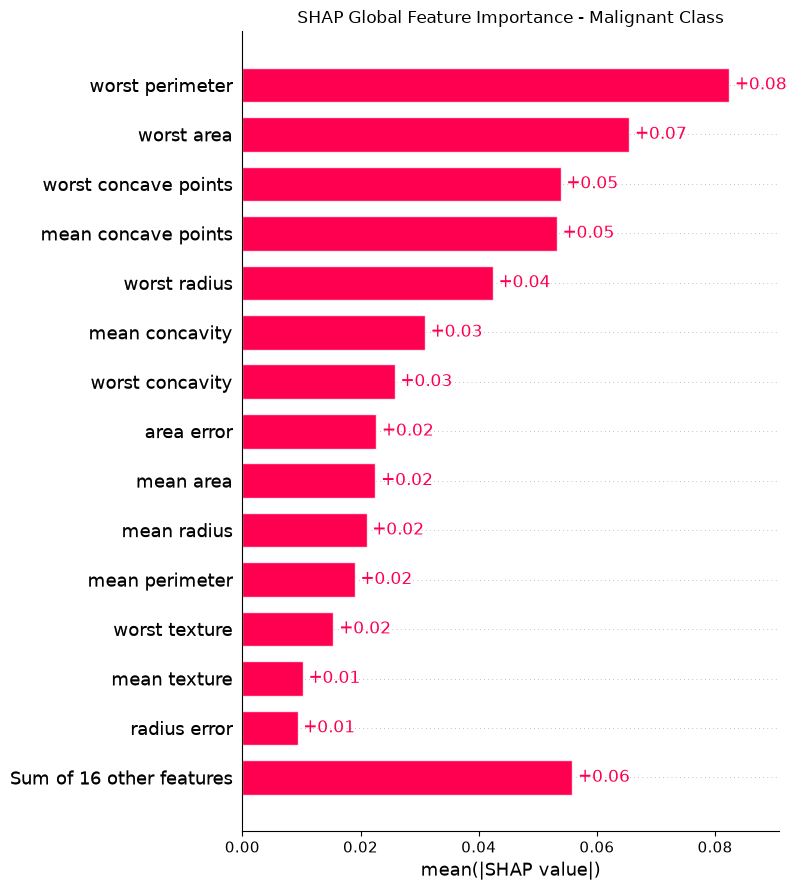

In [8]:
shap.plots.bar(shap_malignant, max_display=15, show=False)
plt.title("SHAP Global Feature Importance - Malignant Class")
plt.tight_layout()
plt.show()

### 6.3 SHAP Summary Plot

The SHAP beeswarm plot shows how each feature influences the model's output across the test samples. Each point represents a sample, and its position indicates the direction and magnitude of the feature's contribution to the malignant-class output.

The point's color represents the feature value, with different colors distinguishing lower and higher values. This plot helps identify important features and understand how their values influence the model's predictions.

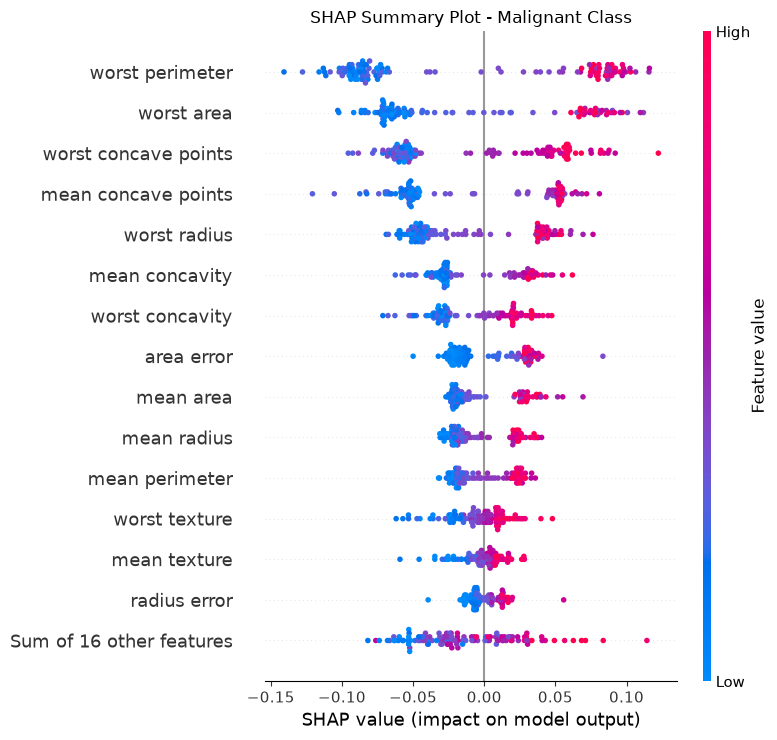

In [9]:
shap.plots.beeswarm(shap_malignant, max_display=15, show=False)
plt.title("SHAP Summary Plot - Malignant Class")
plt.tight_layout()
plt.show()

### 6.4 Explain an Individual Prediction

A single sample from the test set is selected for detailed explanation using both SHAP and LIME. Using the same sample allows us to compare how the two techniques interpret the model's prediction.

The SHAP waterfall plot illustrates how individual feature contributions move the model output from its baseline toward the output for the selected sample. This helps identify which features contribute positively or negatively to the malignant-class prediction.

Sample index: 256
Actual diagnosis: malignant
Predicted diagnosis: malignant
Predicted malignant probability: 1.0000
Predicted benign probability: 0.0000


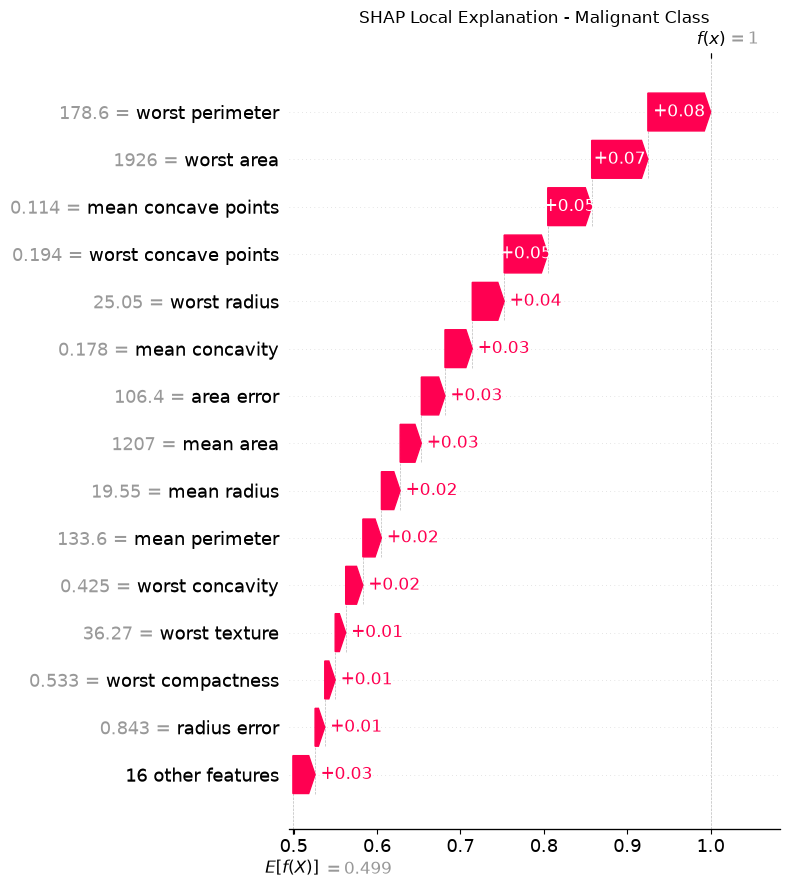

In [10]:
sample_index = 0
sample = X_test.iloc[[sample_index]]
actual_class = int(y_test.iloc[sample_index])
predicted_class = int(model.predict(sample)[0])
predicted_probabilities = model.predict_proba(sample)[0]

print("Sample index:", sample.index[0])
print("Actual diagnosis:", class_names[actual_class])
print("Predicted diagnosis:", class_names[predicted_class])
print(f"Predicted malignant probability: {predicted_probabilities[0]:.4f}")
print(f"Predicted benign probability: {predicted_probabilities[1]:.4f}")

shap.plots.waterfall(shap_malignant[sample_index], max_display=15, show=False)
plt.title("SHAP Local Explanation - Malignant Class")
plt.tight_layout()
plt.show()

## 7. LIME Explainability

LIME (Local Interpretable Model-agnostic Explanations) explains an individual prediction by creating perturbed samples around the selected instance and fitting a simpler, interpretable model locally. This helps identify which features influence the prediction for that specific sample.

Explanations are explicitly generated for both classes, malignant and benign, to ensure that the malignant-class explanation is available even when the model predicts malignant with high probability. The results provide a local explanation that can be compared with SHAP for the same sample.

In [11]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=X_train.columns.tolist(),
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    random_state=RANDOM_STATE,
)

lime_exp = lime_explainer.explain_instance(
    data_row=sample.iloc[0].to_numpy(),
    predict_fn=model.predict_proba,
    labels=(0, 1),
    num_features=15,
    num_samples=5000,
)

print("LIME explanation generated.")
print("Available explanation labels:", lime_exp.available_labels())
print("Actual diagnosis:", class_names[actual_class])
print("Predicted diagnosis:", class_names[predicted_class])

LIME explanation generated.
Available explanation labels: [0, 1]
Actual diagnosis: malignant
Predicted diagnosis: malignant


d:\College\3rd_Year\MLOPS\Assignments\.mlops\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


### 7.1 LIME Local Explanation for the Malignant Class

The LIME explanation highlights the features that contribute to the selected sample's malignant-class prediction. It displays the direction and strength of each feature's contribution within the locally fitted surrogate model.

The visualization helps identify which feature conditions support or oppose the malignant classification for this particular sample. Unlike SHAP's global analysis, this explanation focuses on a single prediction.

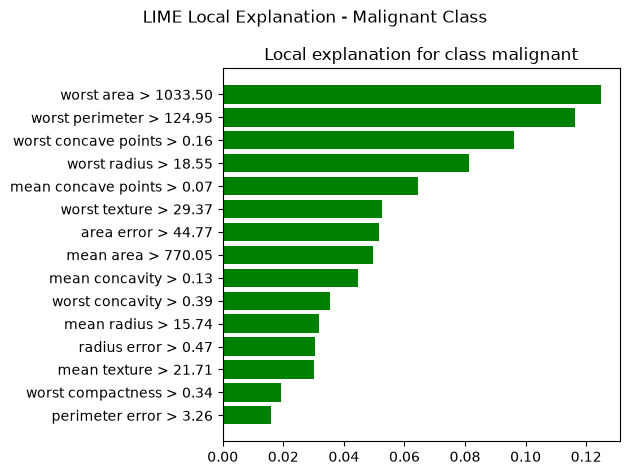

In [12]:
lime_target_label = 0

if lime_target_label not in lime_exp.available_labels():
    raise ValueError(
        f"Malignant class label {lime_target_label} is unavailable. "
        f"Available labels: {lime_exp.available_labels()}"
    )

fig = lime_exp.as_pyplot_figure(label=lime_target_label)
fig.suptitle("LIME Local Explanation - Malignant Class")
fig.tight_layout()
plt.show()

### 7.2 LIME Feature Contributions

The LIME feature contribution plot shows how individual features influence the selected sample's malignant-class prediction. Positive weights support the malignant class in the local surrogate model, while negative weights support the benign class.

These weights help interpret the model's behavior for the selected sample. However, they represent local surrogate-model contributions rather than causal effects, and should not be interpreted as proof that a feature causes a tumor to be malignant.

In [13]:
lime_malignant = pd.DataFrame(
    lime_exp.as_list(label=lime_target_label),
    columns=["Feature Condition", "LIME Weight"],
)
lime_malignant["Absolute Weight"] = lime_malignant["LIME Weight"].abs()
lime_malignant = lime_malignant.sort_values("Absolute Weight", ascending=False)

display(lime_malignant.reset_index(drop=True))

,Feature Condition,LIME Weight,Absolute Weight
0,worst area > 1033.50,0.124910,0.124910
1,worst perimeter > 124.95,0.116453,0.116453
2,worst concave points > 0.16,0.096098,0.096098
3,worst radius > 18.55,0.081461,0.081461
4,mean concave points > 0.07,0.064438,0.064438
5,worst texture > 29.37,0.052501,0.052501
6,area error > 44.77,0.051665,0.051665
7,mean area > 770.05,0.049503,0.049503
8,mean concavity > 0.13,0.044728,0.044728
9,worst concavity > 0.39,0.035469,0.035469


## 8. Compare SHAP and LIME

SHAP and LIME provide complementary insights into the Random Forest model. SHAP global importance summarizes the average magnitude of feature contributions across the test set, while LIME explains the prediction of one selected sample.

The comparison helps identify features highlighted by both techniques and those emphasized differently. Since their scores represent different quantities and use different scales, they should not be compared directly by bar length. Instead, the focus is on the features each method identifies as important.

In [14]:
shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Absolute SHAP": np.abs(malignant_values).mean(axis=0),
}).sort_values("Mean Absolute SHAP", ascending=False)

print("Top 10 SHAP features (global):")
display(shap_importance.head(10).reset_index(drop=True))

print("Top 10 LIME feature conditions (local):")
display(lime_malignant.head(10).reset_index(drop=True))

Top 10 SHAP features (global):


,Feature,Mean Absolute SHAP
0,worst perimeter,0.082377
1,worst area,0.065468
2,worst concave points,0.053859
3,mean concave points,0.053217
4,worst radius,0.042392
5,mean concavity,0.030894
6,worst concavity,0.025786
7,area error,0.022657
8,mean area,0.022515
9,mean radius,0.021014


Top 10 LIME feature conditions (local):


,Feature Condition,LIME Weight,Absolute Weight
0,worst area > 1033.50,0.124910,0.124910
1,worst perimeter > 124.95,0.116453,0.116453
2,worst concave points > 0.16,0.096098,0.096098
3,worst radius > 18.55,0.081461,0.081461
4,mean concave points > 0.07,0.064438,0.064438
5,worst texture > 29.37,0.052501,0.052501
6,area error > 44.77,0.051665,0.051665
7,mean area > 770.05,0.049503,0.049503
8,mean concavity > 0.13,0.044728,0.044728
9,worst concavity > 0.39,0.035469,0.035469


### 8.1 Visual Comparison

The visual comparison presents SHAP global feature importance alongside LIME feature contributions for the same selected sample. It helps identify which features are highlighted by both techniques and how their explanations differ.

SHAP reflects feature importance across the test set, whereas LIME focuses on the selected prediction. Therefore, the plots are used to compare the features identified by each method, not the numerical magnitude of their scores.

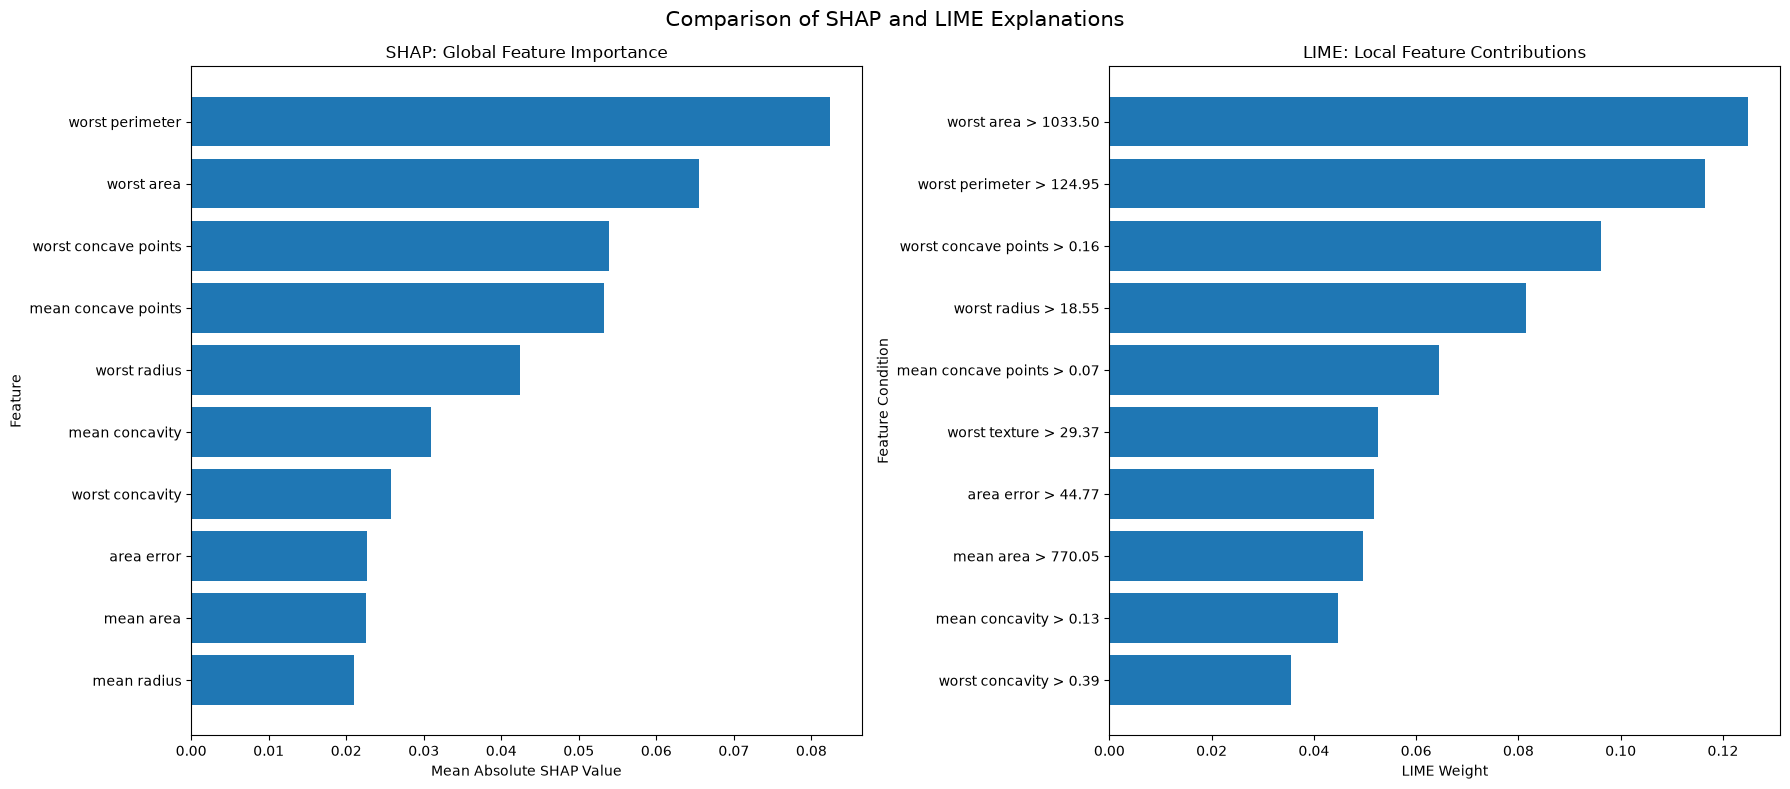

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

shap_top = shap_importance.head(10).sort_values("Mean Absolute SHAP", ascending=True)
axes[0].barh(shap_top["Feature"], shap_top["Mean Absolute SHAP"])
axes[0].set_title("SHAP: Global Feature Importance")
axes[0].set_xlabel("Mean Absolute SHAP Value")
axes[0].set_ylabel("Feature")

lime_top = lime_malignant.head(10).sort_values("LIME Weight", ascending=True)
axes[1].barh(lime_top["Feature Condition"], lime_top["LIME Weight"])
axes[1].set_title("LIME: Local Feature Contributions")
axes[1].set_xlabel("LIME Weight")
axes[1].set_ylabel("Feature Condition")

fig.suptitle("Comparison of SHAP and LIME Explanations", fontsize=15)
plt.tight_layout()
plt.show()

## 9. Conclusion

In this assignment, Explainable Artificial Intelligence techniques were applied to a Random Forest classifier trained on the Breast Cancer Wisconsin Diagnostic dataset.

The model's performance was evaluated using accuracy, macro precision, macro recall, macro F1-score, a classification report, and a confusion matrix. SHAP was used to identify globally influential features and explain an individual prediction. LIME generated a local explanation for the same test sample.

The methods can highlight overlapping features while providing different perspectives: SHAP summarizes feature contributions across the test set and explains individual predictions, whereas LIME approximates the model locally for a particular sample. Their importance values are not directly comparable because they are defined differently.

### Learning Outcomes
- Understood the role of explainability in machine learning.
- Trained and evaluated a Random Forest classifier.
- Applied SHAP for global and local feature attribution.
- Applied LIME for local prediction explanations.
- Compared global feature importance with local feature contributions.
- Recognized limitations of model explanations.

### Limitations
The explanations describe the behavior of this trained model; they do not establish causal relationships or guarantee that a prediction is correct. This dataset and model are for educational purposes only and must not be used for clinical diagnosis.